In [1]:
#these are the liberaies I used for the whole project, but for preprocessing not all of them are used
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import Normalizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd
import numpy as np
import os
#from aerosound.params import *
from keras import Sequential, layers
from keras.metrics import Recall
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

In [2]:
def data_obtain_rnn(path):
# obtain data from the path and saperated the data by machine type and save the dataframes into a dictionary and return to this dictionary
    data_ori = pd.read_csv(path)
    # machine_dfs = {}

    # for machine in data_ori['machine'].unique():
    #     machine_dfs[machine] = data_ori[
    #         data_ori['machine'] == machine
    #     ].copy()

    # print(machine_dfs.keys())
    return data_ori


In [3]:

def prep_data_rnn(data_ori):
    scaler = StandardScaler()
    data = data_ori.copy()
    data = data.drop_duplicates()
    data['label'] = data['label'].map({
        'normal': 0,
        'abnormal': 1
    })
    data = data.drop(columns=['noise','machine','id','file','snr'])
    data = data.rename(columns={'label':'target'})
    X = data.drop(columns = 'target')
    y = data['target']
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=1,
        stratify=y
    )
    X_train_rnn = X_train.to_numpy().reshape(
        X_train.shape[0],
        X_train.shape[1]//2,
        2
    )

    #try: valuable!!!
    #X_train_rnn = X_train_rnn * 100
    X_train_rnn = scaler.fit_transform(
        X_train_rnn.reshape(-1, 2)
    ).reshape(X_train.shape[0], X_train.shape[1]//2, 2)

    # X_test_rnn = X_test.to_numpy().reshape(
    #     X_test.shape[0],
    #     X_test.shape[1],
    #     1
    # )
    return X_train_rnn, X_test, y_train, y_test

In [4]:
def oversample_data(X, y):

    y = np.asarray(y).ravel()

    # Split training and validation data first
    X_train, X_val, y_train, y_val = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=42
    )

    # Oversample training data only
    n_samples, n_steps, n_features = X_train.shape

    X_train_2d = X_train.reshape(n_samples, -1)

    ros = RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )

    X_resampled, y_resampled = ros.fit_resample(
        X_train_2d, y_train
    )

    # Restore 3D shape
    X_resampled = X_resampled.reshape(
        -1, n_steps, n_features
    )

    return X_resampled, X_val, y_resampled, y_val

In [5]:
def rnn_LSTM(X_train_rnn, X_val, y_train, y_val):
    ''' estublish the model, compile the model, train the model '''
    #estublish the model
    model = Sequential([
        layers.Input(shape=(X_train_rnn.shape[1],X_train_rnn.shape[2])),
        layers.LSTM(32),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    #compile the model
    model.compile(
        optimizer = Adam(learning_rate=0.0001, clipnorm=1.0),
        loss = 'binary_crossentropy',
        metrics=[
            Recall(name='recall'),
            'accuracy',
            'AUC'
        ]
    )

    #define early stop
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    #add class weight for abnormal samples, because of unbalanced normal/abnormal data
    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=np.asarray(y_train)
    )
    class_weights = dict(zip(classes, weights))

    #train the model
    history = model.fit(
        X_train_rnn,
        y_train,
        epochs=500,
        batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        class_weight=class_weights
    )
    return model, history

In [ ]:
def predict_sound(model, X_pred):
    ''' predict normal/abnormal '''
    X_pred_rnn = X_pred.to_numpy().reshape(
        X_pred.shape[0],
        X_pred.shape[1]//2,
        2
    )

    #X_pred_rnn = X_pred_rnn * 100
    scaler = StandardScaler()
    X_pred_rnn = scaler.fit_transform(
        X_pred_rnn.reshape(-1, 2)
    ).reshape(X_pred.shape[0], X_pred.shape[1]//2, 2)

    y = model.predict(X_pred_rnn)
    return (y >= 0.4).astype(int), y


In [7]:

def model_evaluate(model, X_test, y_test):
    ''' show the performance of the model '''
    y_pred, y_prob_pred = predict_sound(model, X_test)
    #print(y_pred)
    #print(y_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred.ravel(),
        labels=[0,1],
        display_labels=["Normal", "Abnormal"]
    )

    plt.title("Confusion Matrix")
    plt.show()

In [8]:
print(os.getcwd())

/Users/shaotongwang/code/Marie-Jourdain/aerosound/aerosound/model


In [9]:
data = data_obtain_rnn('0db_fan_stdzcr_100.csv')
data

,noise,machine,id,label,file,snr,f_000,f_001,f_002,f_003,...,f_190,f_191,f_192,f_193,f_194,f_195,f_196,f_197,f_198,f_199
0,0_dB,fan,id_00,abnormal,00000059.wav,0,0.008489,0.047530,0.009500,0.043777,...,0.009530,0.045654,0.010291,0.039400,0.009986,0.028143,0.009617,0.049406,0.009319,0.044403
1,0_dB,fan,id_00,abnormal,00000071.wav,0,0.008590,0.036898,0.009991,0.026892,...,0.010346,0.026892,0.008103,0.031895,0.009203,0.033146,0.008105,0.034396,0.007748,0.040025
2,0_dB,fan,id_00,abnormal,00000065.wav,0,0.010086,0.038149,0.009601,0.053158,...,0.010024,0.045654,0.008293,0.050657,0.008500,0.038149,0.008613,0.037523,0.008502,0.053158
3,0_dB,fan,id_00,abnormal,00000273.wav,0,0.006436,0.055660,0.007534,0.071920,...,0.004920,0.095685,0.005144,0.082552,0.005650,0.083177,0.005638,0.078799,0.005438,0.085053
4,0_dB,fan,id_00,abnormal,00000267.wav,0,0.004283,0.051282,0.003697,0.053784,...,0.006067,0.249531,0.005918,0.207004,0.005611,0.191370,0.005764,0.148218,0.004165,0.158849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5545,0_dB,fan,id_02,normal,00000068.wav,0,0.007421,0.103189,0.007069,0.107567,...,0.006890,0.114447,0.006674,0.101939,0.007352,0.095685,0.007334,0.101939,0.006161,0.119450
5546,0_dB,fan,id_02,normal,00000040.wav,0,0.005930,0.126329,0.006486,0.108818,...,0.007167,0.093183,0.006789,0.101313,0.006511,0.113196,0.006546,0.115072,0.006452,0.115697
5547,0_dB,fan,id_02,normal,00000726.wav,0,0.006656,0.118824,0.006478,0.110694,...,0.006791,0.093183,0.005945,0.132583,0.006180,0.124453,0.005910,0.118199,0.006244,0.109443
5548,0_dB,fan,id_02,normal,00000732.wav,0,0.006282,0.112570,0.006609,0.108818,...,0.006236,0.100688,0.006337,0.092558,0.006249,0.103189,0.005911,0.106942,0.006746,0.099437


In [10]:
X_train_rnn, X_test, y_train, y_test = prep_data_rnn(data)
X_train_rnn

array([[[ 0.03454555,  0.19404597],
        [ 0.37008548, -0.43104003],
        [ 0.07252115, -0.18907126],
        ...,
        [-0.28052905, -0.16890719],
        [-0.34194788,  0.05289752],
        [-0.06864937, -0.20923532]],

       [[-0.36484751,  1.26274137],
        [-0.32703178,  0.41585067],
        [ 0.10408   ,  0.33519442],
        ...,
        [-0.32333483,  0.81913196],
        [-0.27208073,  0.63765538],
        [-0.01801612,  0.53683506]],

       [[-1.33227778, -1.27793073],
        [-1.21788885, -0.63268067],
        [-1.81438254, -0.47136816],
        ...,
        [-1.74785262, -0.28989158],
        [-1.63230725, -0.43104003],
        [-1.51516045, -0.61251661]],

       ...,

       [[-0.47894638,  1.36356169],
        [-0.14062879,  0.7384757 ],
        [-0.47707507,  1.38372576],
        ...,
        [ 0.42450742,  0.65781944],
        [ 0.45456229,  0.69814757],
        [-0.31845822,  0.85946009]],

       [[ 0.49204494,  0.87962415],
        [-0.41557326,  1.34

In [11]:
X_resampled, X_val, y_resampled, y_val = oversample_data(X_train_rnn, y_train)

In [12]:
y_resampled_df = pd.DataFrame(y_resampled.reshape(y_resampled.shape[0], -1))
print(y_resampled_df[0].value_counts(1))
print(y_resampled_df[0].value_counts(0))

0
0    0.5
1    0.5
Name: proportion, dtype: float64
0
0    2608
1    2608
Name: count, dtype: int64


In [13]:
y_val_df = pd.DataFrame(y_val.reshape(y_val.shape[0], -1))
print(y_val_df[0].value_counts(1))
print(y_val_df[0].value_counts(0))

0
0    0.734234
1    0.265766
Name: proportion, dtype: float64
0
0    652
1    236
Name: count, dtype: int64


In [14]:
model_rnn, history = rnn_LSTM(X_resampled, X_val, y_resampled, y_val)

Epoch 1/500
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - AUC: 0.5847 - accuracy: 0.5780 - loss: 0.6857 - recall: 0.4958 - val_AUC: 0.7126 - val_accuracy: 0.6194 - val_loss: 0.6787 - val_recall: 0.7034
Epoch 2/500
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.6904 - accuracy: 0.6390 - loss: 0.6608 - recall: 0.6733 - val_AUC: 0.7286 - val_accuracy: 0.6318 - val_loss: 0.6683 - val_recall: 0.7076
Epoch 3/500
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.7124 - accuracy: 0.6641 - loss: 0.6370 - recall: 0.6764 - val_AUC: 0.7394 - val_accuracy: 0.7162 - val_loss: 0.6387 - val_recall: 0.6568
Epoch 4/500
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.7257 - accuracy: 0.6967 - loss: 0.6041 - recall: 0.5851 - val_AUC: 0.7381 - val_accuracy: 0.7770 - val_loss: 0.5956 - val_recall: 0.5890
Epoch 5/500
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.7443 - accuracy: 0.7168 - loss: 0.5720 - recall: 0.5456 - val_AUC: 0.7531 - val_accuracy: 0.8052 - val_loss: 0.5349 - val_recall: 0.5339
Epoc

In [15]:
std = X_train_rnn[:, :, 0]
zcr = X_train_rnn[:, :, 1]

print("STD:")
print("Min:", std.min())
print("Max:", std.max())
print("Mean:", std.mean())
print("Std:", std.std())
print("Variance:", std.var())

print("\nZCR:")
print("Min:", zcr.min())
print("Max:", zcr.max())
print("Mean:", zcr.mean())
print("Std:", zcr.std())
print("Variance:", zcr.var())

STD:
Min: -3.7595080920521258
Max: 11.743123737990977
Mean: -3.9962203716329583e-14
Std: 0.9999999999999946
Variance: 0.9999999999999892

ZCR:
Min: -2.6289230329052145
Max: 9.308203019818853
Mean: -1.515919241986315e-13
Std: 0.9999999999997385
Variance: 0.9999999999994771


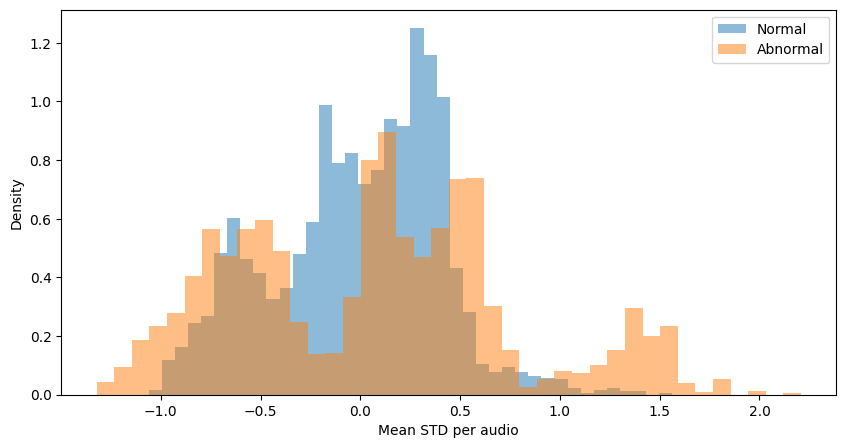

In [16]:
# Average STD feature per audio sample
sample_means = X_resampled.mean(axis=(1, 2))

normal_means = sample_means[y_resampled == 0]
abnormal_means = sample_means[y_resampled == 1]

plt.figure(figsize=(10, 5))

plt.hist(normal_means, bins=40, alpha=0.5,
         density=True, label="Normal")

plt.hist(abnormal_means, bins=40, alpha=0.5,
         density=True, label="Abnormal")

plt.xlabel("Mean STD per audio")
plt.ylabel("Density")
plt.legend()
plt.show()

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


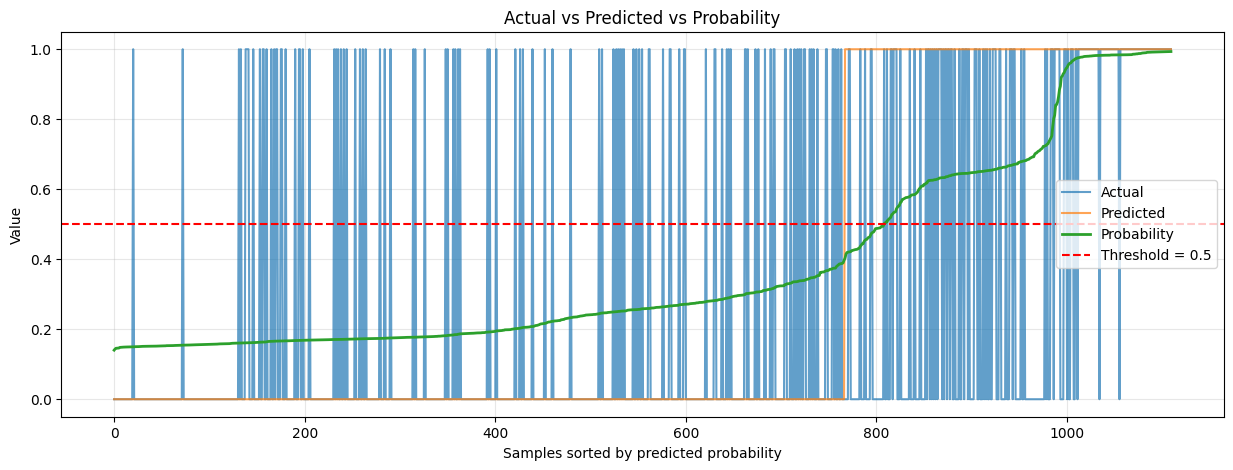

In [20]:
classified_pred, prob_pred = predict_sound(model_rnn, X_test)
y_test_plot = np.asarray(y_test).ravel()
y_pred_plot = np.asarray(classified_pred).ravel()
y_prob_plot = np.asarray(prob_pred).ravel()
visu = pd.DataFrame({'y_true':y_test_plot, 'y_pred':y_pred_plot, 'y_prob':y_prob_plot})
visu = visu.sort_values(by='y_prob').reset_index(drop=True)

# Plot
plt.figure(figsize=(15, 5))

plt.plot(visu['y_true'], label='Actual', alpha=0.7)
plt.plot(visu['y_pred'], label='Predicted', alpha=0.7)
plt.plot(visu['y_prob'], label='Probability', linewidth=2)

plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')

plt.xlabel('Samples sorted by predicted probability')
plt.ylabel('Value')
plt.title('Actual vs Predicted vs Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


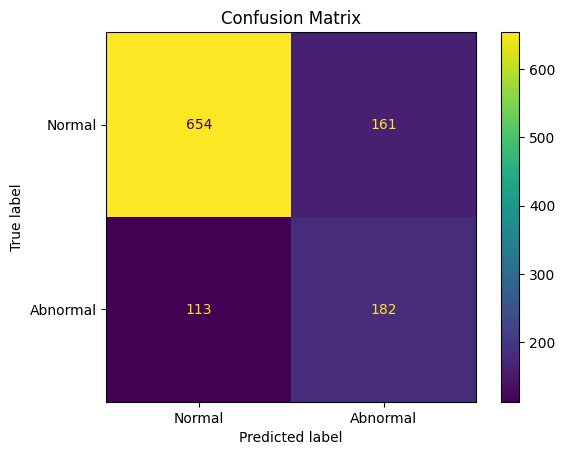

In [21]:
model_evaluate(model_rnn, X_test, y_test)

In [22]:
model_rnn.save("lstm_stdzcr_100_0.86_0.71.keras")